In [7]:
import pandas as pd

In [8]:
import numpy as np

In [9]:
import matplotlib.pyplot as plt

In [10]:
import seaborn as sns

In [11]:
df = pd.read_csv("/content/Churn_Modelling.csv")

In [12]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [14]:
print(df["Exited"].value_counts())

Exited
0    7963
1    2037
Name: count, dtype: int64


In [15]:
Churn_rate = df["Exited"].mean() *100
print(Churn_rate)

20.369999999999997


In [16]:
print(f"Customer Churn rate : {Churn_rate:.2f}%")

Customer Churn rate : 20.37%


In [17]:
Churn_count = df["Exited"].map({
    0:"stayed",
    1:"Exited"
}).value_counts()

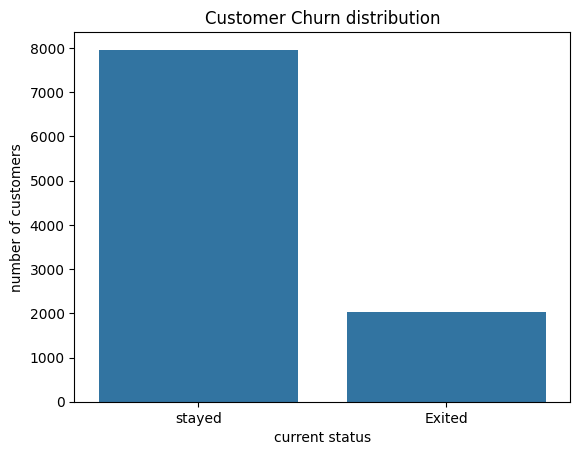

In [18]:
sns.barplot(x=Churn_count.index,y=Churn_count.values)
plt.title("Customer Churn distribution")
plt.xlabel("current status")
plt.ylabel("number of customers")
plt.show()

In [19]:
df["agegroup"] = pd.cut(
    df["Age"],
    bins = [0,25,35,45,55,65,100],
    labels = ["18-25",
              "26-35",
              "36-45",
              "46-55",
              "56-65",
              "66+"
              ]

)

In [20]:
age_Churn = df.groupby(
    "agegroup",
    observed = False
)["Exited"].mean() *100

print(f"Churn rate by age group: {age_Churn.round(2)}")

Churn rate by age group: agegroup
18-25     7.53
26-35     8.50
36-45    19.62
46-55    50.57
56-65    48.32
66+      13.26
Name: Exited, dtype: float64


CUSTOMER CHURN ANALYSIS BYGENDER

In [21]:
gender_churn = df.groupby("Gender")["Exited"].mean() *100

print(f"churn rate by gender:{gender_churn.round(2)}")

churn rate by gender:Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64


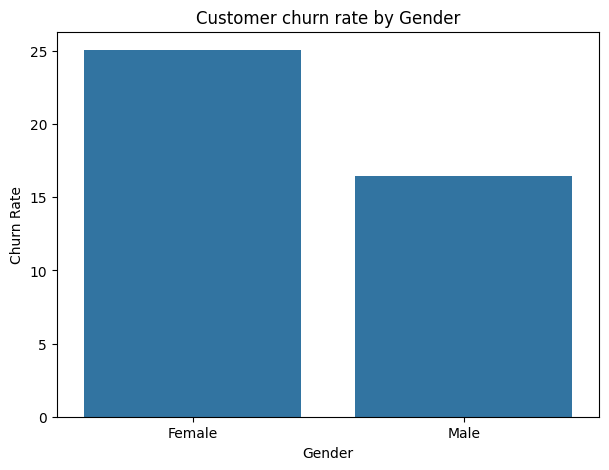

In [22]:
plt.figure(figsize=(7,5))
sns.barplot(x=gender_churn.index, y=gender_churn.values)
plt.title("Customer churn rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate")
plt.show()

In [23]:
print("churn rate by gender")
print(gender_churn.round(2))
print(f"customer count by gender{df["Gender"].value_counts()}")
print(f"Customer who exited by gender: {df[df["Exited"] == 1]["Gender"].value_counts()}")



churn rate by gender
Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64
customer count by genderGender
Male      5457
Female    4543
Name: count, dtype: int64
Customer who exited by gender: Gender
Female    1139
Male       898
Name: count, dtype: int64


ANALYZE CHURN BY GEOGRAPHY

In [24]:
geo_churn = df.groupby("Geography")["Exited"].mean() * 100


print(f"churn rate by geography: {geo_churn.round(2)}")

churn rate by geography: Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64


In [25]:
geo_churn

,Exited
Geography,
France,16.154767
Germany,32.443204
Spain,16.673395


Text(0, 0.5, 'churn rate(%)')

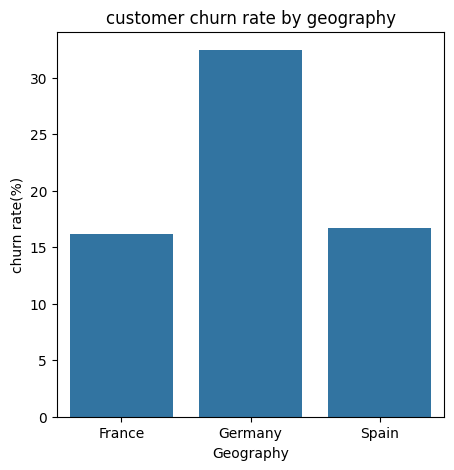

In [26]:
plt.figure(figsize =(5,5))

sns.barplot(x=geo_churn.index,y=geo_churn.values)
plt.title("customer churn rate by geography")
plt.xlabel("Geography")
plt.ylabel("churn rate(%)")

CHURN ANALYZE BY THE NUMBER OF BANK PRODUCTS

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   RowNumber        10000 non-null  int64   
 1   CustomerId       10000 non-null  int64   
 2   Surname          10000 non-null  object  
 3   CreditScore      10000 non-null  int64   
 4   Geography        10000 non-null  object  
 5   Gender           10000 non-null  object  
 6   Age              10000 non-null  int64   
 7   Tenure           10000 non-null  int64   
 8   Balance          10000 non-null  float64 
 9   NumOfProducts    10000 non-null  int64   
 10  HasCrCard        10000 non-null  int64   
 11  IsActiveMember   10000 non-null  int64   
 12  EstimatedSalary  10000 non-null  float64 
 13  Exited           10000 non-null  int64   
 14  agegroup         10000 non-null  category
dtypes: category(1), float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [28]:
product_churn = df.groupby("NumOfProducts")["Exited"].mean() *100
print(f"Customer churn rate by product: {product_churn.round(2)}")

Customer churn rate by product: NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64


Text(0, 0.5, 'churn rate (%)')

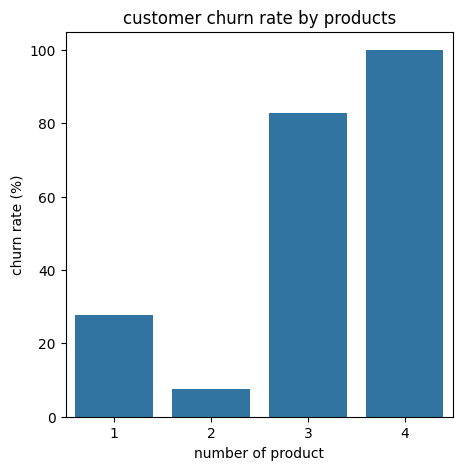

In [29]:
plt.figure(figsize = (5,5))

sns.barplot(x=product_churn.index,y=product_churn.values)
plt.title("customer churn rate by products")
plt.xlabel("number of product")
plt.ylabel("churn rate (%)")

In [30]:
print("Customer churn by number of products")

df["NumOfProducts"].value_counts().sort_index()



Customer churn by number of products


,count
NumOfProducts,
1,5084
2,4590
3,266
4,60


In [31]:
print("churn status by number of products\n\n")
print(pd.crosstab(
    df["NumOfProducts"],
    df["Exited"],
    margins=True
))

churn status by number of products


Exited            0     1    All
NumOfProducts                   
1              3675  1409   5084
2              4242   348   4590
3                46   220    266
4                 0    60     60
All            7963  2037  10000


CHURN ANALYSIS BY ACTIVE MEMBERSHIP

In [33]:
activity_churn = df.groupby("IsActiveMember")["Exited"].mean()*100

In [39]:
print(f"churn rate by active membership:activity_churn.round(2)")

churn rate by active membership:activity_churn.round(2)


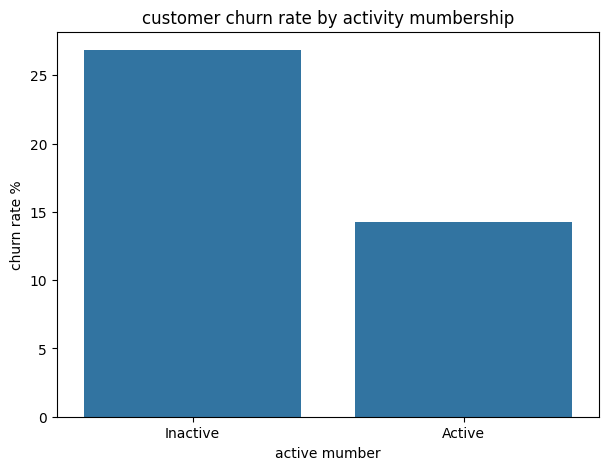

In [42]:
plt.figure("figsize",(7,5))

sns.barplot(x=activity_churn.index,
            y=activity_churn.values

            )
plt.title("customer churn rate by activity mumbership")
plt.xlabel("active mumber")
plt.ylabel("churn rate %")
plt.xticks([0, 1], ["Inactive", "Active"])
plt.show()

In [38]:
Tenure_churn = df.groupby("Tenure")["Exited"].mean()*100

In [40]:
print(f"churn rate by Tenure:Tenure_churn.round(2)")

churn rate by Tenure:Tenure_churn.round(2)


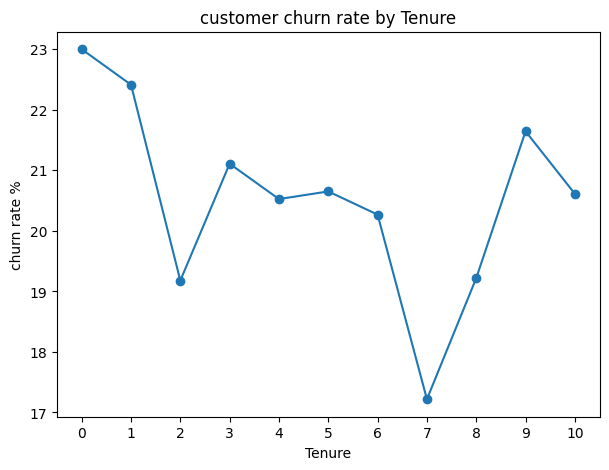

In [47]:
plt.figure("figsize",(7,5))
plt.plot(
    Tenure_churn.index,
    Tenure_churn.values,
    marker ='o'
)
plt.title("customer churn rate by Tenure")
plt.xlabel("Tenure")
plt.ylabel("churn rate %")

plt.xticks(range(0,11))
plt.show()

In [54]:
df["creditscoregroup"]=pd.cut(
    df["CreditScore"],
    bins = [0,580,670,740,800,1000],
    labels =[
        "poor",
        "fair",
        "good",
        "very good",
        "excellent"
     ],
    include_lowest= True
    )




In [56]:
credit_churn = (
    df.groupby("creditscoregroup",observed = False)["Exited"].mean()*100

)
print(f"churn rate by credit score:{credit_churn.round(2)}")

churn rate by credit score:creditscoregroup
poor         22.15
fair         20.39
good         18.82
very good    20.25
excellent    19.69
Name: Exited, dtype: float64


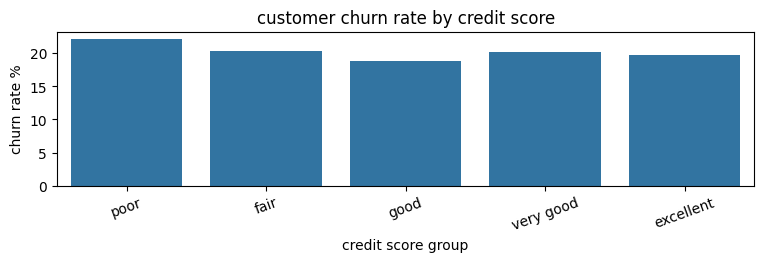

In [57]:
plt.figure(figsize=(9,2))
sns.barplot(
    x=credit_churn.index,
    y=credit_churn.values
)
plt.title("customer churn rate by credit score")
plt.xlabel("credit score group")
plt.ylabel("churn rate %")
plt.xticks(rotation = 20)
plt.show()

In [64]:
df["BalanceGroup"] =pd.qcut(
    df["Balance"],
    q=5,
    duplicates="drop"
)

In [65]:
balance_churn = (
    df.groupby("BalanceGroup", observed=False)["Exited"].mean()*100
)
print(f"churn rate by account balance:balance_churn.round(2)")

churn rate by account balance:balance_churn.round(2)


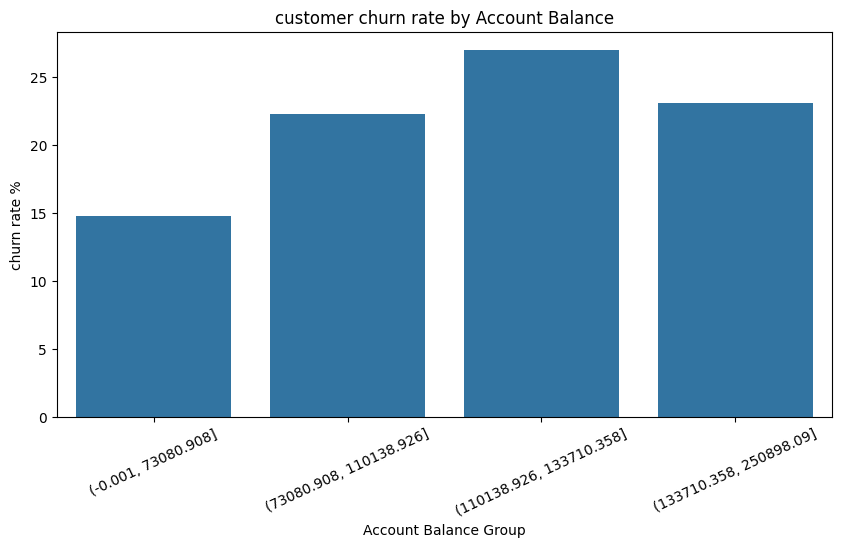

In [66]:
plt.figure(figsize=(10,5))
sns.barplot(
    x=balance_churn.index.astype(str),
    y=balance_churn.values
)
plt.title("customer churn rate by Account Balance")
plt.xlabel("Account Balance Group")
plt.ylabel("churn rate %")
plt.xticks(rotation=25)
plt.show()

In [67]:
card_churn = df.groupby("HasCrCard")["Exited"].mean() * 100


print("Churn rate by credit card ownership:")
print(card_churn.round(2))

Churn rate by credit card ownership:
HasCrCard
0    20.81
1    20.18
Name: Exited, dtype: float64


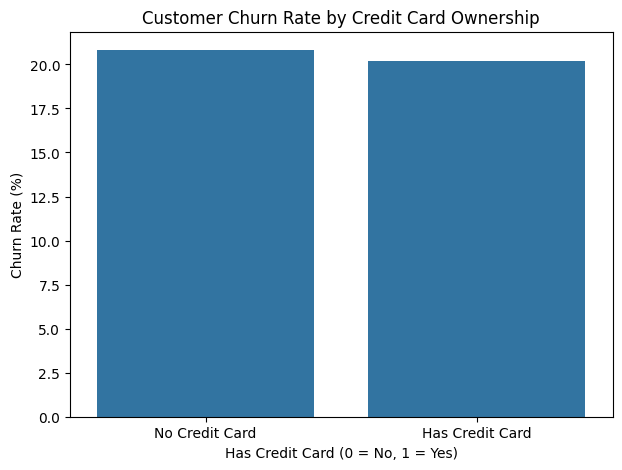

In [68]:
plt.figure(figsize=(7, 5))


sns.barplot(
    x=card_churn.index,
    y=card_churn.values
)


plt.title("Customer Churn Rate by Credit Card Ownership")
plt.xlabel("Has Credit Card (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks([0, 1], ["No Credit Card", "Has Credit Card"])


plt.show()

In [69]:
df["SalaryGroup"] = pd.qcut(
    df["EstimatedSalary"],
    q=5,
    duplicates="drop"
)


# Calculate churn rate by salary group
salary_churn = (
    df.groupby("SalaryGroup", observed=False)["Exited"]
    .mean() * 100
)


print("Churn rate by estimated salary:")
print(salary_churn.round(2))

Churn rate by estimated salary:
SalaryGroup
(11.579, 41050.736]         19.95
(41050.736, 80238.34]       19.95
(80238.34, 119710.038]      20.20
(119710.038, 159836.726]    20.20
(159836.726, 199992.48]     21.55
Name: Exited, dtype: float64


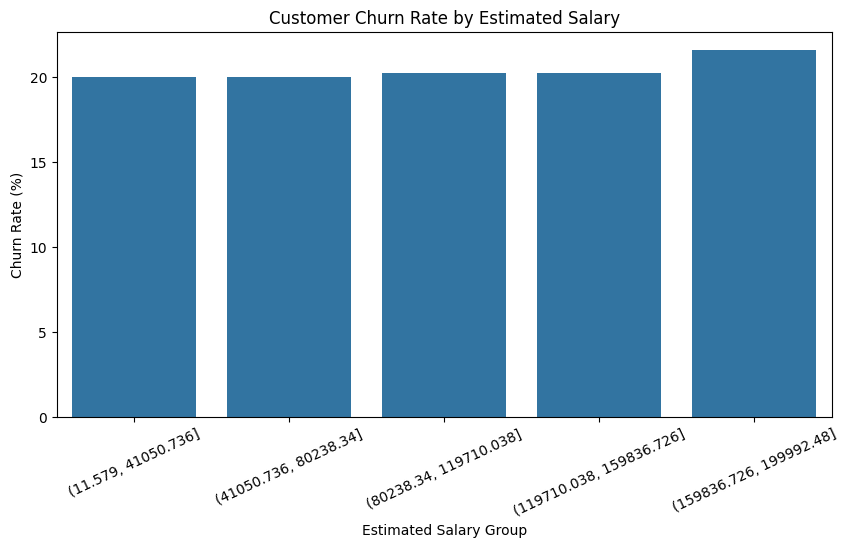

In [70]:
plt.figure(figsize=(10, 5))


sns.barplot(
    x=salary_churn.index.astype(str),
    y=salary_churn.values
)


plt.title("Customer Churn Rate by Estimated Salary")
plt.xlabel("Estimated Salary Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25)


plt.show()